# FL-SEC-001.1 — Cryptographic approach selection (HE / SecAgg / SMPC)

*Epic EPIC-001 · story fl_sec_001 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Select, with explicit criteria and evidence, the cryptographic aggregation mechanisms to implement for healthcare FL, and document assumptions. Output: a decision matrix with theoretical properties separated from measured costs.

## 2. Scientific background
Three families protect model updates from the aggregator: homomorphic encryption (CKKS [cheon2017], BFV [fv2012], Paillier [paillier1999]), pairwise-masking secure aggregation [bonawitz2017, bell2020] and secret-sharing MPC (SPDZ-style [damgard2012, beaver1991]). They differ in trust assumptions, dropout handling and cost; none protects against poisoning.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Which mechanisms satisfy the story's requirements (server learns only the aggregate; correctness; dropout tolerance)?
- **RQ2.** What are the measured per-update costs of the HE schemes at the model size used?

## 4. Hypotheses
- **H1.** CKKS gives the lowest ciphertext expansion among HE schemes for float vectors, BFV is exact up to quantisation, Paillier is the most expensive.
- **H2.** SecAgg is cheapest in bandwidth but requires dropout machinery.

## 5. Mathematical formulation
CKKS encodes a real vector into a polynomial ring element and supports additive aggregation with error ε ≈ 2^{-scale}; BFV works over Z_t with fixed-point quantisation q(x)=round(x·2^f); Paillier: Enc(m)=g^m r^n mod n², Enc(a)·Enc(b)=Enc(a+b). Shamir t-of-n sharing over a prime field. Weighted mean: w̄ = Σ p_k Δ_k, p_k = n_k/Σn.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_sec_001"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_sec_001


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
print("No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.")
print(json.dumps(json.load(open(next(RES.glob("*.json"))))["provenance"]["config"], indent=1)[:800])

No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.
{
 "P": 1442,
 "n": 10,
 "parties": [
  2,
  3,
  5
 ],
 "clients": [
  5,
  10,
  20
 ]
}


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`crypto/he.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.privacy.homomorphic import CKKSAggregator, BFVAggregator
rng = np.random.default_rng(SEED); D = rng.normal(0, .1, (4, 300)).astype(np.float32); W = np.array([10., 20., 30., 40.])
ref = (W / W.sum()) @ D
for A in (CKKSAggregator(), BFVAggregator()):
    out = A.aggregate(D, W); err = float(np.abs(out - ref).max()); print(type(A).__name__, "max abs error vs plaintext:", err, "| keygen:", {k: A.keygen_info()[k] for k in A.keygen_info() if "secret" in k})
    assert err < 1e-4
print("server context holds no secret key (key-holder model) -> asserted in tests/")

CKKSAggregator max abs error vs plaintext: 1.1175870895385742e-08 | keygen: {'secret_in_server_ctx': False}
BFVAggregator max abs error vs plaintext: 1.5409663319584238e-06 | keygen: {'secret_in_server_ctx': False}
server context holds no secret key (key-holder model) -> asserted in tests/


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-SEC-001.1` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_1_1_he_comparison_measured.csv')
show_csv('task_1_1_protocol_comparison_theoretical.csv')

,scheme,measured_vector_len,max_abs_error,ct_bytes_per_float32,expansion_vs_float32,enc_ms_per_client,enc_us_per_element,agg_ms,dec_ms,arithmetic,plaintext_domain,security_basis,fit
0,CKKS,1442,0.0,229.6401,57.410,9.6587,6.6981,5.4357,2.1589,approximate over reals (additions and multipli...,"real/complex vectors, SIMD","RLWE (ring-LWE), post-quantum assumptions",best for real-valued updates; error ~1e-8 obse...
1,BFV,1442,0.0,299.8918,74.973,7.6706,5.3194,8.1403,4.0734,"exact modular integer arithmetic, SIMD",integers mod t (needs fixed-point encoding),RLWE,exact but forces quantisation and a plaintext-...
2,Paillier,32,0.0,512.0000,128.000,3339.6983,104365.5707,20.6418,927.4350,additive only (plus scalar multiplication),integers mod n (float via exponent encoding),decisional composite residuosity; broken by qu...,no SIMD: one ciphertext per coordinate -> impr...


,approach,computes,threat_model,crypto,server_sees_individual_update,limits
0,Secure aggregation (pairwise masking),sum of client vectors only,honest-but-curious server (+ colluding clients...,"ECDH, PRG masks, Shamir sharing",False,only linear aggregation; cannot run robust (me...
1,HE (CKKS/BFV) aggregation,sums (and limited depth products) under encryp...,honest-but-curious server; secret-key holder m...,RLWE lattice encryption,False,"ciphertext expansion, single secret key => key..."
2,"SMPC (SPDZ-style, m computing parties)","arbitrary arithmetic circuits (here: sum, squa...",dishonest majority among m servers (m-1 corrup...,additive sharing + information-theoretic MAC +...,False,m servers must be non-colluding organisations;...


## 12. Metrics collection
Metric definitions: ciphertext bytes/client, expansion factor, enc/agg/dec time (MEASURED); security properties (THEORETICAL, from the cited papers).

In [8]:
show_csv('task_1_1_he_comparison_measured.csv')

,scheme,measured_vector_len,max_abs_error,ct_bytes_per_float32,expansion_vs_float32,enc_ms_per_client,enc_us_per_element,agg_ms,dec_ms,arithmetic,plaintext_domain,security_basis,fit
0,CKKS,1442,0.0,229.6401,57.410,9.6587,6.6981,5.4357,2.1589,approximate over reals (additions and multipli...,"real/complex vectors, SIMD","RLWE (ring-LWE), post-quantum assumptions",best for real-valued updates; error ~1e-8 obse...
1,BFV,1442,0.0,299.8918,74.973,7.6706,5.3194,8.1403,4.0734,"exact modular integer arithmetic, SIMD",integers mod t (needs fixed-point encoding),RLWE,exact but forces quantisation and a plaintext-...
2,Paillier,32,0.0,512.0000,128.000,3339.6983,104365.5707,20.6418,927.4350,additive only (plus scalar multiplication),integers mod n (float via exponent encoding),decisional composite residuosity; broken by qu...,no SIMD: one ciphertext per coordinate -> impr...


## 13. Statistical analysis
Single-configuration microbenchmark with repeated timing; no hypothesis test. Cost-vs-size scaling is analysed in task 1.2.

In [9]:
J = json.load(open(RES / 'task_1_1_decision_matrix.json')); print(list(J.keys()))

['provenance', 'he', 'protocols', 'decision']


## 14. Visualizations

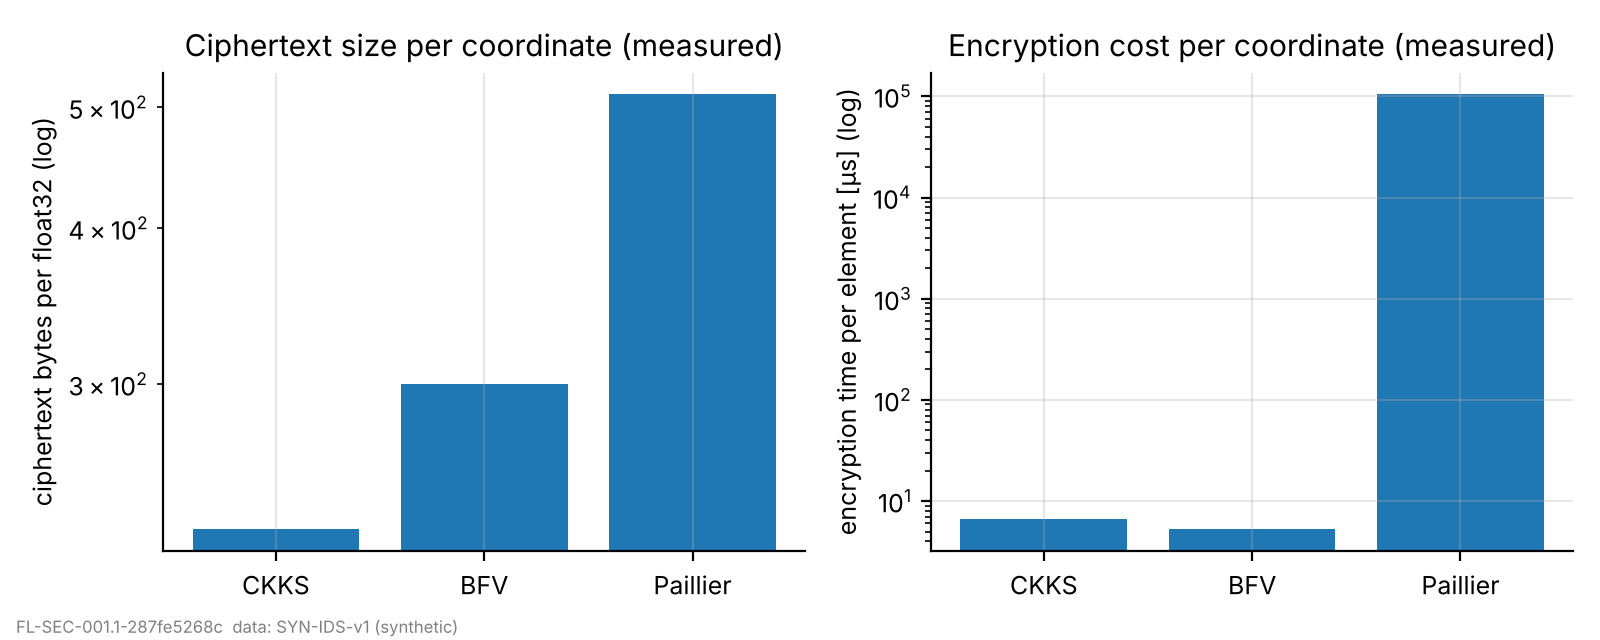

In [10]:
show_fig('task_1_1_he_cost.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

The decision matrix distinguishes *measured* rows from *theoretical* rows; no scheme is declared 'secure' based on timings.

In [11]:
J = json.load(open(RES / 'task_1_1_decision_matrix.json')); print(json.dumps({k: J[k] for k in J if k != 'provenance'}, indent=1)[:2500])

{
 "he": [
  {
   "scheme": "CKKS",
   "measured_vector_len": 1442,
   "max_abs_error": 1.3959604305835427e-08,
   "ct_bytes_per_float32": 229.64008321775313,
   "expansion_vs_float32": 57.41002080443828,
   "enc_ms_per_client": 9.658670999999686,
   "enc_us_per_element": 6.698107489597563,
   "agg_ms": 5.4357439999819235,
   "dec_ms": 2.1589309999967554,
   "arithmetic": "approximate over reals (additions and multiplications, rescaling)",
   "plaintext_domain": "real/complex vectors, SIMD",
   "security_basis": "RLWE (ring-LWE), post-quantum assumptions",
   "fit": "best for real-valued updates; error ~1e-8 observed"
  },
  {
   "scheme": "BFV",
   "measured_vector_len": 1442,
   "max_abs_error": 1.9024566307243584e-06,
   "ct_bytes_per_float32": 299.89181692094314,
   "expansion_vs_float32": 74.97295423023579,
   "enc_ms_per_client": 7.670595199999752,
   "enc_us_per_element": 5.319414147017858,
   "agg_ms": 8.1403379999756,
   "dec_ms": 4.073441000002731,
   "arithmetic": "exact mod

## 16. Limitations
- Security claims are taken from the literature, not verified here.
- Only TenSEAL/phe backends were measured.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
All three families were implemented in this sprint; the choice is use-case dependent (see decision matrix).

**Jira acceptance:** see `docs/fl_sec_001/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`cheon2017`, `fv2012`, `paillier1999`, `bonawitz2017`, `damgard2012`, `kairouz2021` — details in `docs/fl_sec_001/references.md`.